# 01 - Exploratory Data Analysis

Goal: understand the ASEADOS-SDN-IoT dataset before training any model: its size, columns, classes and data quality problems.

This notebook only reads the data. All cleaning is done in `02_preprocessing.ipynb`, based on the findings here.

## 1. Load the data

The CSV is not in the repository (231 MB). Download it from https://aseados.ucd.ie/datasets/SDN-IoT/ and save it as `data/ASEADOS_SDN_IoT.csv`.

In [27]:
CSV_PATH = '../data/ASEADOS_SDN_IoT.csv'
LABEL = 'Label'

In [28]:
import numpy as np
import pandas as pd

df = pd.read_csv(CSV_PATH, low_memory=False)
df.columns = df.columns.str.strip()   # remove spaces around column names
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (457044, 84)


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,8.128.192.168-85.245.192.168-0-0-0,85.245.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:04 PM,3241760,1,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot
1,8.128.192.168-31.125.192.168-0-0-0,31.125.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:08 PM,17649667,1,1,...,0,0.0,0.0,0.0,0.0,17649667.0,0.0,17649667.0,17649667.0,Bot
2,8.128.192.168-82.28.192.168-0-0-0,82.28.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:07 PM,24923670,1,1,...,0,0.0,0.0,0.0,0.0,24923670.0,0.0,24923670.0,24923670.0,Bot
3,8.128.192.168-76.22.192.168-0-0-0,76.22.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:27 PM,5399930,1,1,...,0,0.0,0.0,0.0,0.0,5399930.0,0.0,5399930.0,5399930.0,Bot
4,8.128.192.168-72.128.192.168-0-0-0,72.128.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:27 PM,5436008,1,1,...,0,0.0,0.0,0.0,0.0,5436008.0,0.0,5436008.0,5436008.0,Bot


The dataset has **457,044 rows and 84 columns**: 83 flow features and the `Label` column.

## 2. Columns and data types

In [29]:
print(df.dtypes.value_counts())
print()
text_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print('Text (object) columns:', text_cols)

float64    45
int64      34
object      5
Name: count, dtype: int64

Text (object) columns: ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label']


79 columns are numeric and 5 are text. The text columns are the identifiers (`Flow ID`, `Src IP`, `Dst IP`, `Timestamp`) and the label.

## 3. Class distribution

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

         count  percent (%)
Label                      
Benign  260797        57.06
Dos     127772        27.96
DDoS     51465        11.26
Bot       9090         1.99
Prob      7920         1.73


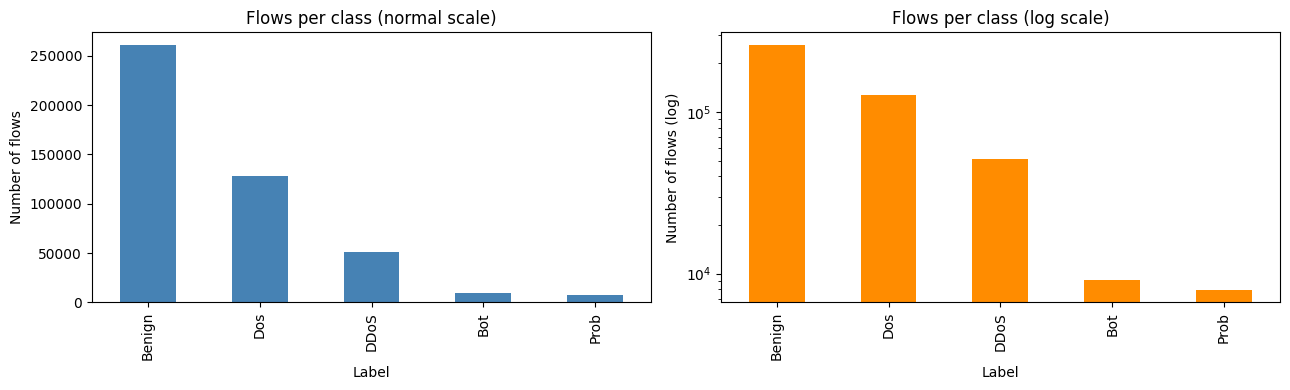

In [31]:
counts = df[LABEL].value_counts()
table = pd.DataFrame({'count': counts, 'percent (%)': (counts / len(df) * 100).round(2)})
print(table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Flows per class (normal scale)')
axes[0].set_ylabel('Number of flows')

counts.plot(kind='bar', ax=axes[1], color='darkorange', logy=True)
axes[1].set_title('Flows per class (log scale)')
axes[1].set_ylabel('Number of flows (log)')
plt.tight_layout()
plt.show()

- The classes are **highly imbalanced**: Benign 57.06%, Dos 27.96%, DDoS 11.26%, Bot 1.99%, Prob 1.73%.
- Bot and Prob are almost invisible on the normal scale. The log scale makes them visible.
- The label spellings in the CSV are `Benign`, `Dos`, `DDoS`, `Bot` and `Prob` (not `DoS` / `Probe`). The code must use these exact names.

## 4. Missing and infinite values

CICFlowMeter can produce `inf` when it divides by zero (for example, packets per second for a flow with zero duration). Models cannot handle NaN or inf values.

In [32]:
num = df.select_dtypes(include=np.number)

nan_per_col = df.isna().sum()
inf_per_col = np.isinf(num).sum()

print('Total NaN cells :', int(nan_per_col.sum()))
print('Total inf cells :', int(inf_per_col.sum()))
print()
print('Columns with NaN:')
print(nan_per_col[nan_per_col > 0])
print()
print('Columns with inf:')
print(inf_per_col[inf_per_col > 0])

bad_rows = (df.isna().any(axis=1) | np.isinf(num).any(axis=1))
print()
print(f'Rows with at least one NaN or inf: {bad_rows.sum()} ({bad_rows.mean()*100:.2f}% of all rows)')

Total NaN cells : 66
Total inf cells : 74

Columns with NaN:
Flow Byts/s    66
dtype: int64

Columns with inf:
Flow Byts/s     4
Flow Pkts/s    70
dtype: int64

Rows with at least one NaN or inf: 70 (0.02% of all rows)


- 66 NaN cells, all in `Flow Byts/s`.
- 74 inf cells: 4 in `Flow Byts/s` and 70 in `Flow Pkts/s`.
- In total only **70 rows (0.02%)** are affected. The same 70 rows have problems in both "per second" columns, so they are probably flows with zero duration. These rows will be removed.

## 5. Duplicate rows

In [33]:
dup = df.duplicated()
print(f'Duplicate rows: {dup.sum()} ({dup.mean()*100:.2f}%)')
print()
print('Duplicates per class:')
print(df[dup][LABEL].value_counts())

Duplicate rows: 0 (0.00%)

Duplicates per class:
Series([], Name: count, dtype: int64)


There are no exact duplicates, because every row has its own `Flow ID` and `Timestamp`. Without the identifier columns, there are 29,993 duplicate rows (see section 10).

## 6. Constant columns

A column with the same value in every row gives the model no information.

In [34]:
nunique = df.nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
print('Number of constant columns:', len(constant_cols))
print(constant_cols)

Number of constant columns: 14
['Fwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Init Fwd Win Byts', 'Fwd Seg Size Min']


**14 columns are constant** (for example `Fwd URG Flags`, `CWE Flag Count`, `Fwd Byts/b Avg`). They will be removed.

## 7. Identifier columns and data leakage

IPs, ports and timestamps describe *who* sent the traffic and *when*, not *how* it behaves. If one of them is strongly linked to a class, the model can learn a shortcut instead of real attack behaviour.

In [35]:
id_keywords = ['flow id', 'src ip', 'dst ip', 'source ip', 'destination ip',
               'src port', 'dst port', 'source port', 'destination port', 'timestamp']
id_cols = [c for c in df.columns if c.lower() in id_keywords]
print('Identifier columns found:', id_cols)
print()

for col in id_cols:
    if col.lower() == 'flow id':
        continue   # almost every value is unique, nothing to see here
    top = df[col].value_counts().head(5).index
    print(f'--- {col}: label share for its 5 most common values ---')
    print(pd.crosstab(df[col][df[col].isin(top)], df[LABEL], normalize='index').round(2))
    print()

Identifier columns found: ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Timestamp']

--- Src IP: label share for its 5 most common values ---
Label           Benign   Dos
Src IP                      
192.168.4.17      0.85  0.15
192.168.4.9       1.00  0.00
192.168.40.150    0.99  0.01
192.168.40.152    1.00  0.00
200.175.2.130     0.00  1.00

--- Src Port: label share for its 5 most common values ---
Label     Benign   Bot  DDoS   Dos  Prob
Src Port                                
0           0.34  0.07   0.4  0.13  0.06
22          1.00  0.00   0.0  0.00  0.00
80          0.00  0.00   0.0  1.00  0.00
443         1.00  0.00   0.0  0.00  0.00
3000        1.00  0.00   0.0  0.00  0.00

--- Dst IP: label share for its 5 most common values ---
Label           Benign   Bot  DDoS   Dos
Dst IP                                  
192.168.20.131    0.08  0.00  0.00  0.92
192.168.4.17      0.26  0.00  0.00  0.74
192.168.4.9       1.00  0.00  0.00  0.00
192.168.40.150    0.09  0.00  0.00

- The source IP `200.175.2.130` is **100% Dos**. This is most likely the attacker machine.
- Port 80 is 100% Dos, while ports 22, 443, 3000 and 5000 are 100% Benign.
- Each attack type was recorded on a **different day** (Prob on 10/02, Bot on 12/03, Dos on 24/03), so the timestamp alone can reveal the class.
- Port 0 appears in every class, and Bot, DDoS and Prob flows have port 0 only.

Decision: all six identifier columns (`Flow ID`, `Src IP`, `Src Port`, `Dst IP`, `Dst Port`, `Timestamp`) will be removed to avoid data leakage.

## 8. Basic statistics

In [36]:
desc = num.replace([np.inf, -np.inf], np.nan).describe().T
desc[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
Src Port,2.950951e+04,2.333366e+04,0.0,38494.0,6.099800e+04
Dst Port,5.376827e+03,1.346059e+04,0.0,80.0,6.099800e+04
Protocol,4.367177e+00,2.789368e+00,0.0,6.0,1.700000e+01
Flow Duration,1.681224e+07,3.050907e+07,-475223.0,162714.0,1.199996e+08
Tot Fwd Pkts,1.040191e+01,1.944271e+02,0.0,2.0,3.099000e+04
...,...,...,...,...,...
Active Min,2.588285e+05,1.730258e+06,0.0,0.0,1.140417e+08
Idle Mean,1.243249e+07,2.459949e+07,0.0,0.0,1.199960e+08
Idle Std,7.814503e+05,4.123237e+06,0.0,0.0,7.562769e+07
Idle Max,1.323179e+07,2.534387e+07,0.0,0.0,1.199960e+08


- `Flow Duration` has a **negative minimum** (-475,223). A duration cannot be negative, so these values are noise.
- The scales of the features are very different (from 0 to about 10^8). Logistic Regression will need feature scaling; tree-based models do not.

## 9. Comparing classes on key features

Boxplots on a log scale, using a sample of up to 3,000 flows per class. Values are shifted by +1 so that zeros can be shown on the log scale (a value of 1 on the plot means 0).

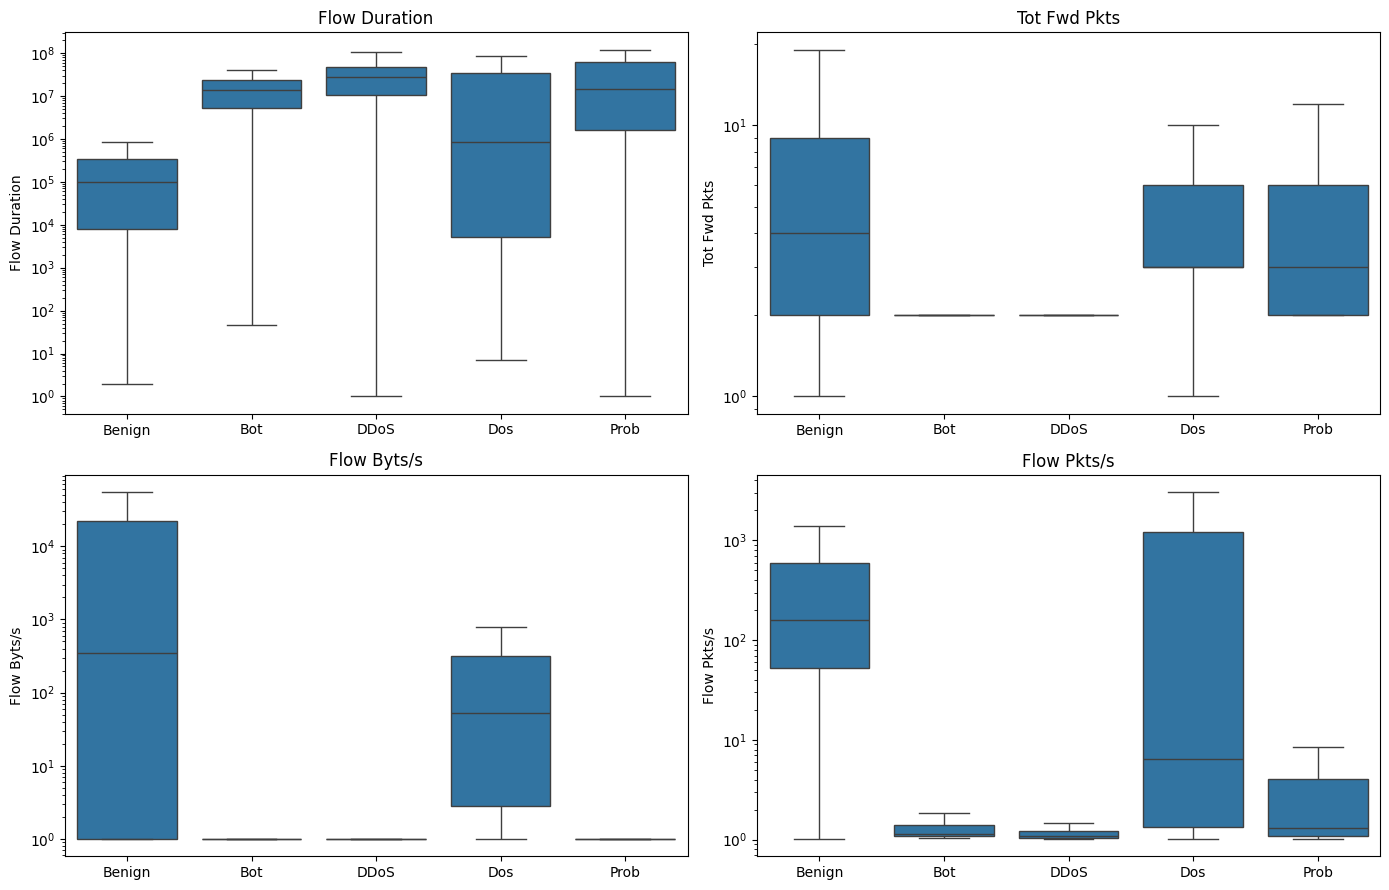

In [37]:
features = ['Flow Duration', 'Tot Fwd Pkts', 'Flow Byts/s', 'Flow Pkts/s']
sample = pd.concat([g.sample(min(len(g), 3000), random_state=42) for _, g in df.groupby(LABEL)])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), features):
    data = sample[[col, LABEL]].replace([np.inf, -np.inf], np.nan).dropna()
    data[col] = data[col].clip(lower=0) + 1
    sns.boxplot(data=data, x=LABEL, y=col, ax=ax, showfliers=False)
    ax.set_yscale('log')
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

- **Benign flows are much shorter** than attack flows: the median `Flow Duration` of Benign is around 10^5, while Bot, DDoS and Prob are around 10^7. This supports the paper's claim that benign and malicious traffic are clearly separable.
- **Bot and DDoS look almost the same**: one forward packet, zero bytes per second and a very low packet rate. The model may confuse these two classes.
- Bot, DDoS and Prob have `Flow Byts/s` = 0. Together with port 0 (section 7), this suggests that the packet contents of these flows were not parsed.
- Dos is spread over a wide range, which makes it overlap with Benign on some features.

## 10. Highly correlated features

Pairs with correlation > 0.95: 40
Tot Bwd Pkts      Subflow Bwd Pkts    1.000
Tot Fwd Pkts      Subflow Fwd Pkts    1.000
Bwd Pkt Len Mean  Bwd Seg Size Avg    1.000
TotLen Fwd Pkts   Subflow Fwd Byts    1.000
Bwd PSH Flags     PSH Flag Cnt        1.000
Fwd Pkt Len Mean  Fwd Seg Size Avg    1.000
TotLen Bwd Pkts   Subflow Bwd Byts    1.000
Bwd Header Len    Subflow Bwd Pkts    1.000
Tot Bwd Pkts      Bwd Header Len      1.000
Flow IAT Max      Idle Max            1.000
Pkt Len Mean      Pkt Size Avg        0.999
Tot Bwd Pkts      Subflow Bwd Byts    0.994
Subflow Bwd Pkts  Subflow Bwd Byts    0.994
Tot Bwd Pkts      TotLen Bwd Pkts     0.994
TotLen Bwd Pkts   Subflow Bwd Pkts    0.994
dtype: float64


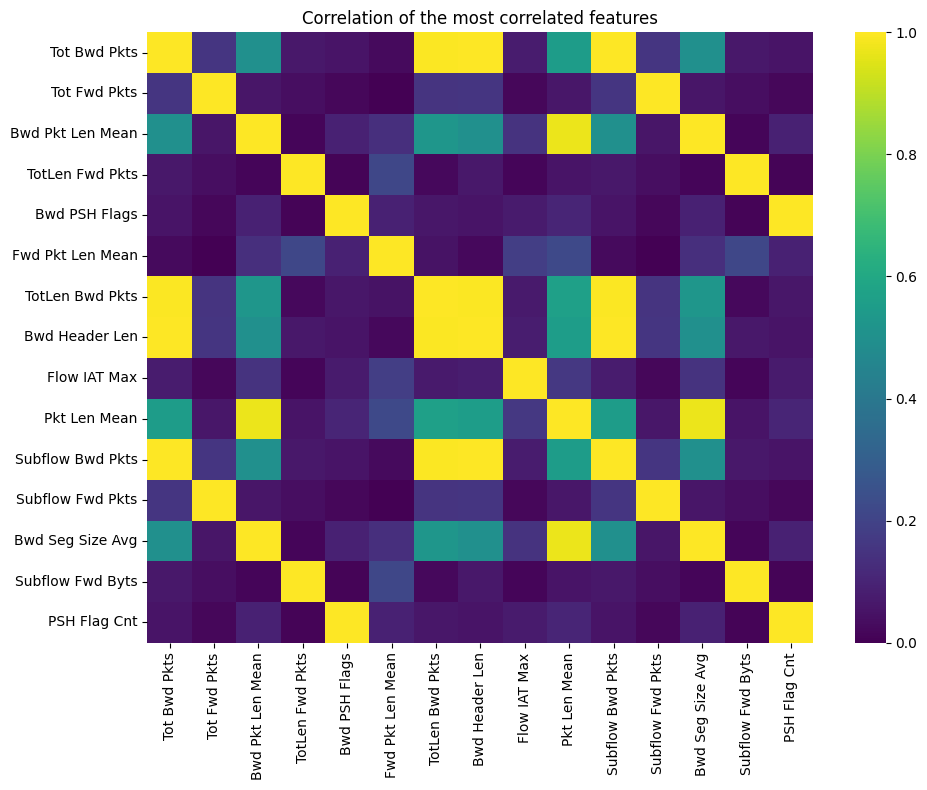

In [38]:
clean_num = num.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how='all')
clean_num = clean_num.loc[:, clean_num.nunique() > 1]
corr = clean_num.sample(min(len(clean_num), 50000), random_state=42).corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print('Pairs with correlation > 0.95:', int((pairs > 0.95).sum()))
print(pairs.head(15).round(3))

top = pd.Index(pairs.head(15).index.get_level_values(0)).append(pd.Index(pairs.head(15).index.get_level_values(1))).unique()[:15]
plt.figure(figsize=(10, 8))
sns.heatmap(corr.loc[top, top], cmap='viridis', vmin=0, vmax=1)
plt.title('Correlation of the most correlated features')
plt.tight_layout()
plt.show()

40 feature pairs have a correlation above 0.95. Some carry exactly the same information, for example `Tot Fwd Pkts` and `Subflow Fwd Pkts` (1.000). This is not a problem for tree-based models, but it can be useful to remove one feature from each pair for Logistic Regression.

## 11. Extra checks

Negative durations, the relation between `Protocol` and the label, and duplicates after removing the identifier columns.

In [39]:
# 1) Negative values in duration
print('Negative Flow Duration rows:', (df['Flow Duration'] < 0).sum())

# 2) Protocol vs label: is Protocol also a shortcut?
print(pd.crosstab(df['Protocol'], df[LABEL]))

# 3) Duplicates after removing ID columns
id_cols = ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Timestamp']
print('Duplicates without ID columns:', df.drop(columns=id_cols).duplicated().sum())

Negative Flow Duration rows: 2
Label     Benign   Bot   DDoS     Dos  Prob
Protocol                                   
0          42740  9090  51465   16075  7920
6         216512     0      0  111654     0
17          1545     0      0      43     0
Duplicates without ID columns: 29993


- Only **2 rows** have a negative `Flow Duration`. They will be removed.
- **All Bot, DDoS and Prob flows have `Protocol` = 0**, while TCP (6) and UDP (17) appear only in Benign and Dos. Protocol 0 is not a real protocol, so it probably means the headers could not be read. `Protocol` is a shortcut and will be removed.
- Without the identifier columns there are **29,993 duplicate rows**, most of them Benign. They will be removed after the column cleaning.

## 12. Summary

| Finding | Decision | Where |
| --- | --- | --- |
| Strong class imbalance (Bot 1.99%, Prob 1.73%) | Stratified split; macro F1 as main metric; class weights | Preprocessing; evaluation; training |
| 70 rows with NaN / inf | Remove | Preprocessing |
| 14 constant columns | Remove | Preprocessing |
| Identifier columns linked to classes | Remove all six | Preprocessing |
| `Protocol` = 0 for all Bot, DDoS and Prob flows | Remove `Protocol` | Preprocessing |
| 2 negative durations | Remove | Preprocessing |
| 29,993 duplicates without identifiers | Remove (last step) | Preprocessing |
| Very different feature scales | Scale for Logistic Regression only | Training (inside the Pipeline) |
| Bot and DDoS look very similar | Check the confusion matrix | Evaluation |